# OPIS, Gotthard and beam pointing
Compare train-resolved OPIS photon energies with the mean of the accepted single-shot Gotthard centres. Works for fixed-energy delay scans and undulator scans. Use the stored single-shot centres when available; otherwise extract them from the combined VLS frames in chunks. No changes are made to the H5 files.

The reference calibration is always run 60560 unless explicitly changed in the header. The fallback extraction follows the documented `photon_energy.py` approach but is not a bit-for-bit reproduction (see Section 2). OPIS is sparse and is matched on the recorded train axis, without interpolation. A valid record does not guarantee that OPIS measures exactly the same pulses as Gotthard.

## 1. Load data and parameters
Change `FILE` here only and run the notebook from the top. The original delay-scan file is selected by default; the undulator scan is an alternative.

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
from scipy.ndimage import uniform_filter1d

COMBINED_DIR = Path('/asap3/flash/gpfs/fl24/2026/data/11024642/processed/combined')

# FILE = COMBINED_DIR / 'Ethanol_long_delay_scan_1_271_5eV_2809305821.h5'
FILE = COMBINED_DIR / 'run60586_Ethanol_undulator_scan_265-272eV_2808708850.h5'
VLS_CAL_FILE = COMBINED_DIR / 'run60560_Ethanol_undulator_scan_2808016357.h5'

GMD_MIN = 0.02                 # µJ
BUNCH_RANGE = (0, 100)
TRAIN_RATE = 10                # Hz
GOTTHARD_TOL_EV = 3.0          # train mean vs nominal; None disables this cut
SETTLE_TRAINS = 30             # for within-step analysis of undulator scans
MIN_TRAINS = 10

# VLS extraction (used only when stored shot centres are absent)
VLS_ROI = (200, 650)
CM_ROI = (650, 800)
DARK_SLOT = 100
BAD_PIXELS = [291, 292, 679, 680, 681]
COM_HALF_WIDTH = 30
SMOOTH = 9
MIN_SNR = 5.0
CHUNK_TRAINS = 32

# Optional spectral diagnostics, only when full VLS frames are available.
N_OPIS_BINS = 6
SPECTRA_NOMINAL = None         # None: fixed-energy run or middle matched energy step
PLOT_ROI = None                # None: show full ROI; e.g. (450, 600)
NORMALISE_PEAK = True
SHOW_EXAMPLES = True

with h5py.File(FILE, 'r') as f:
    tid = f['tID'][:]
    mpe = f['mpe'][:]
    gmd = f['gmd'][:]
    nominal = f['nominal_energy'][:]
    hor_pos = f['hor_pos'][:]
    ver_pos = f['ver_pos'][:]
    has_vls = 'vls' in f
    has_centres = 'photon_energy/vls_centre' in f
    has_measured = 'photon_energy/measured' in f

with h5py.File(VLS_CAL_FILE, 'r') as f:
    cal_coef = f['photon_energy/cal_coef'][:]
    cal_px = f['photon_energy/cal_centres'][:]
    cal_E = f['photon_energy/cal_energies'][:]

assert all(a.shape == tid.shape for a in (mpe, nominal, hor_pos, ver_pos))
assert gmd.shape[0] == len(tid)
assert np.all(np.diff(tid) > 0), 'Check train order and duplicate train IDs'

time_min = (tid.astype(float) - float(tid[0])) / TRAIN_RATE / 60
valid_opis = np.isfinite(mpe) & (mpe > 0)
b0, b1 = BUNCH_RANGE
G = gmd[:, b0:b1]
valid_gmd = np.isfinite(G) & (G >= GMD_MIN)

nominal_round = np.round(nominal, 3)
steps = np.unique(nominal_round[np.isfinite(nominal_round) & (nominal_round > 0)])
is_undulator = len(steps) > 1

print(FILE.name)
print(f'Trains: {len(tid):,} | OPIS valid: {valid_opis.sum():,} ({valid_opis.mean():.2%})')
print(f'OPIS NaN: {np.isnan(mpe).sum():,} | zero: {(mpe == 0).sum():,}')
print(f'Full VLS: {has_vls} | Stored shot centres: {has_centres} | Stored energies: {has_measured}')
print('Nominal energies:', steps)
print('Reference calibration:', cal_coef)
print('Calibration RMS (eV):', np.sqrt(np.mean((np.polyval(cal_coef, cal_px) - cal_E)**2)))

run60586_Ethanol_undulator_scan_265-272eV_2808708850.h5
Trains: 92,074 | OPIS valid: 7,904 (8.58%)
OPIS NaN: 84,141 | zero: 29
Full VLS: False | Stored shot centres: True | Stored energies: True
Nominal energies: [265.  265.5 266.  266.5 267.  267.5 268.  268.5 269.  269.5 270.  270.5
 271.  271.5 272. ]
Reference calibration: [-5.90511927e-02  2.98986902e+02]
Calibration RMS (eV): 0.07455633448733763


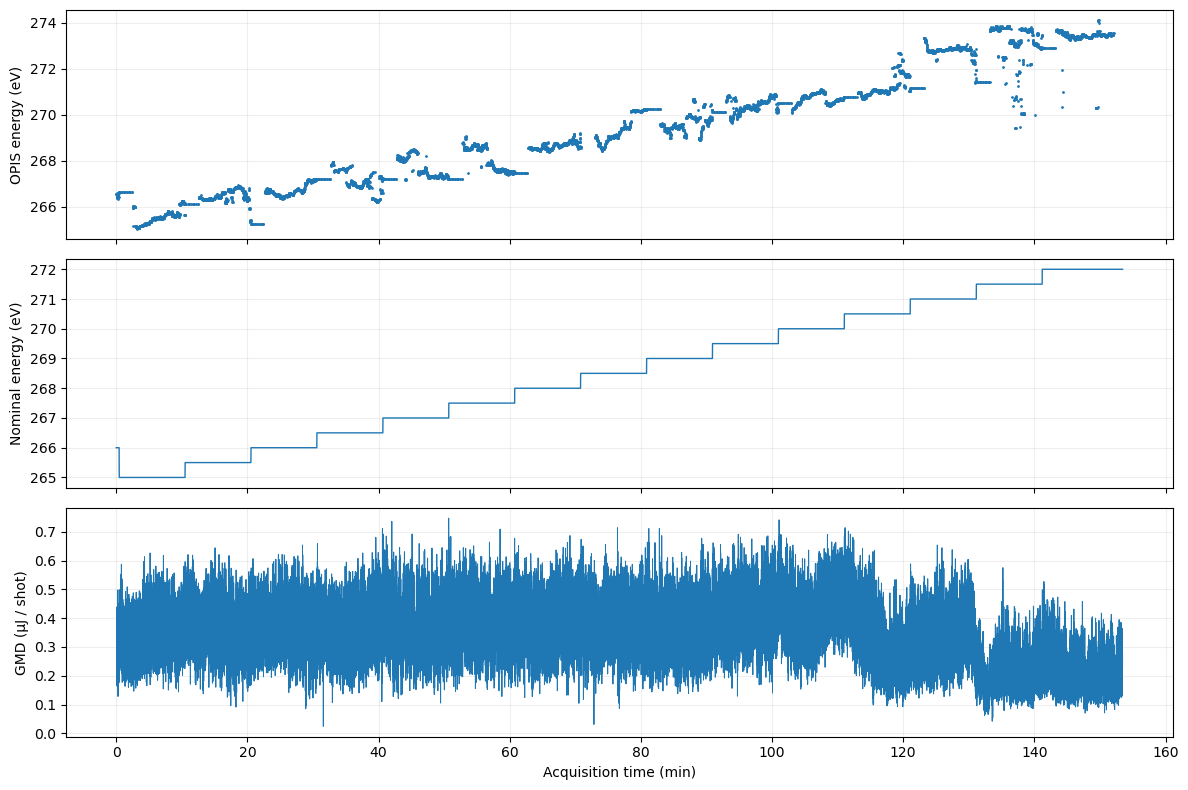

In [59]:
# OPIS, machine setting and pulse energy versus acquisition time.
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

ax[0].plot(time_min[valid_opis], mpe[valid_opis], '.', ms=2)
ax[0].set_ylabel('OPIS energy (eV)')
if not valid_opis.any():
    ax[0].text(0.5, 0.5, 'No valid OPIS records', transform=ax[0].transAxes, ha='center')

ax[1].plot(time_min, nominal, lw=1)
ax[1].set_ylabel('Nominal energy (eV)')

# Mean of recorded finite GMD values, before applying the pulse-energy cut.
ng = np.isfinite(G).sum(axis=1)
gmd_train = np.divide(np.nansum(np.where(np.isfinite(G), G, np.nan), axis=1), ng,
                      out=np.full(len(tid), np.nan), where=ng > 0)
ax[2].plot(time_min, gmd_train, lw=0.7)
ax[2].set_ylabel('GMD (µJ / shot)')
ax[2].set_xlabel('Acquisition time (min)')

for a in ax:
    a.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 2. Single-shot Gotthard centres
Both paths give an array of shot centres in pixels. Stored centres are preferred and, when available, the finite `measured` mask retains the original extraction's valid-shot selection; its *energy values* are not used, since we keep the 60560 calibration.

If only full VLS frames are present, subtract a run-mean dark pedestal and the per-shot median in the common-mode ROI. Locate the peak using a 9-pixel smoothed spectrum, then calculate the centre of mass of the unsmoothed positive signal within ±30 pixels. Reject windows crossing the ROI boundary and weak signals using a threshold estimated from dark windows (median + 5 standard deviations of signed window sums). This is a notebook fallback, not a verified numerical copy of `photon_energy.py`; compare both on a common run before pooling precise results. The combined VLS data already have the bunch offset applied. No full VLS array is loaded into RAM.

In [60]:
# Small shared VLS helpers (also used for the optional spectral plots).
px = np.arange(*VLS_ROI)
read_roi = slice(VLS_ROI[0], CM_ROI[1])
cm_slice = slice(CM_ROI[0] - VLS_ROI[0], CM_ROI[1] - VLS_ROI[0])
cm_good = ~np.isin(np.arange(*CM_ROI), BAD_PIXELS)


def correct_vls(V, dark):
    V = V.astype(np.float32) - dark
    V -= np.nanmedian(V[..., cm_slice][..., cm_good], axis=-1, keepdims=True)
    V = V[..., :len(px)].copy()
    V[..., np.isin(px, BAD_PIXELS)] = 0
    return V


def spectral_centres(V):
    # Last axis = pixel. Return centre and signed signal in the COM window.
    peak = uniform_filter1d(V, size=SMOOTH, axis=-1, mode='nearest').argmax(axis=-1)
    window = np.abs(np.arange(len(px)) - peak[..., None]) <= COM_HALF_WIDTH
    signal = np.where(window, V, 0).sum(axis=-1)
    weights = np.where(window, np.maximum(V, 0), 0)
    total = weights.sum(axis=-1)
    centre = np.divide((weights * px).sum(axis=-1), total,
                       out=np.full(total.shape, np.nan), where=total > 0)
    good = (np.isfinite(V).all(axis=-1) & (peak >= COM_HALF_WIDTH) &
            (peak < len(px) - COM_HALF_WIDTH))
    return np.where(good, centre, np.nan), signal


shot_centres = np.full(G.shape, np.nan, dtype=np.float32)
shot_signal = np.full(G.shape, np.nan, dtype=np.float32)
dark = None

if has_centres:
    with h5py.File(FILE, 'r') as f:
        shot_centres[:] = f['photon_energy/vls_centre'][:, b0:b1]
        if has_measured:
            measured_ok = np.isfinite(f['photon_energy/measured'][:, b0:b1])
            shot_centres[~measured_ok] = np.nan
        if 'photon_energy/vls_window_sum' in f:
            shot_signal[:] = f['photon_energy/vls_window_sum'][:, b0:b1]
    print('Using stored single-shot centres')

elif not has_vls:
    print('No VLS frames or stored centres. Recover from raw FLASH files first.')

if has_vls:
    # Only the dark slot is read over the whole run (a small fraction of the data).
    with h5py.File(FILE, 'r') as f:
        dark_lines = f['vls'][:, DARK_SLOT, read_roi]
    dark = np.nanmean(dark_lines, axis=0, dtype=np.float64).astype(np.float32)
    if not has_centres:
        dark_corrected = correct_vls(dark_lines, dark)
        dark_centre, dark_signal = spectral_centres(dark_corrected)
        noise = dark_signal[np.isfinite(dark_centre) & np.isfinite(dark_signal)]
        assert len(noise) > 1, 'No usable dark spectra'
        threshold = np.median(noise) + MIN_SNR * np.std(noise)
        print(f'Notebook dark-window threshold: {threshold:.1f} ADU')

        with h5py.File(FILE, 'r') as f:
            for start in range(0, len(tid), CHUNK_TRAINS):
                sl = slice(start, start + CHUNK_TRAINS)
                V = correct_vls(f['vls'][sl, b0:b1, read_roi], dark)
                centre, signal = spectral_centres(V)
                shot_centres[sl] = np.where(signal > threshold, centre, np.nan)
                shot_signal[sl] = signal
        print('Using notebook single-shot extraction')
    del dark_lines

# Same GMD selection for both extraction paths.
keep_shot = valid_gmd & np.isfinite(shot_centres)
vls_nshots = keep_shot.sum(axis=1)
centre_train = np.divide(np.where(keep_shot, shot_centres, 0).sum(axis=1, dtype=float),
                         vls_nshots, out=np.full(len(tid), np.nan), where=vls_nshots > 0)
gotthard_E = np.polyval(cal_coef, centre_train)

# Train-level quality cut around nominal energy, independent of OPIS.
valid_vls = np.isfinite(gotthard_E)
if GOTTHARD_TOL_EV is not None:
    has_nominal = np.isfinite(nominal) & (nominal > 0)
    valid_vls &= ~has_nominal | (np.abs(gotthard_E - nominal) <= GOTTHARD_TOL_EV)

matched = valid_opis & valid_vls
print(f'Accepted VLS shots before train cut: {keep_shot.sum():,}')
print(f'Valid VLS trains: {valid_vls.sum():,} / {(vls_nshots > 0).sum():,} with centres')
print(f'Matched OPIS–VLS trains: {matched.sum():,}')

Using stored single-shot centres
Accepted VLS shots before train cut: 8,834,453
Valid VLS trains: 92,037 / 92,037 with centres
Matched OPIS–VLS trains: 7,901


## 3. OPIS vs Gotthard


OPIS:     269.4019 ± 2.4728 eV (mean ± SD)
Gotthard: 268.5722 ± 2.2939 eV (mean ± SD)
Gotthard - OPIS: -0.8296 eV


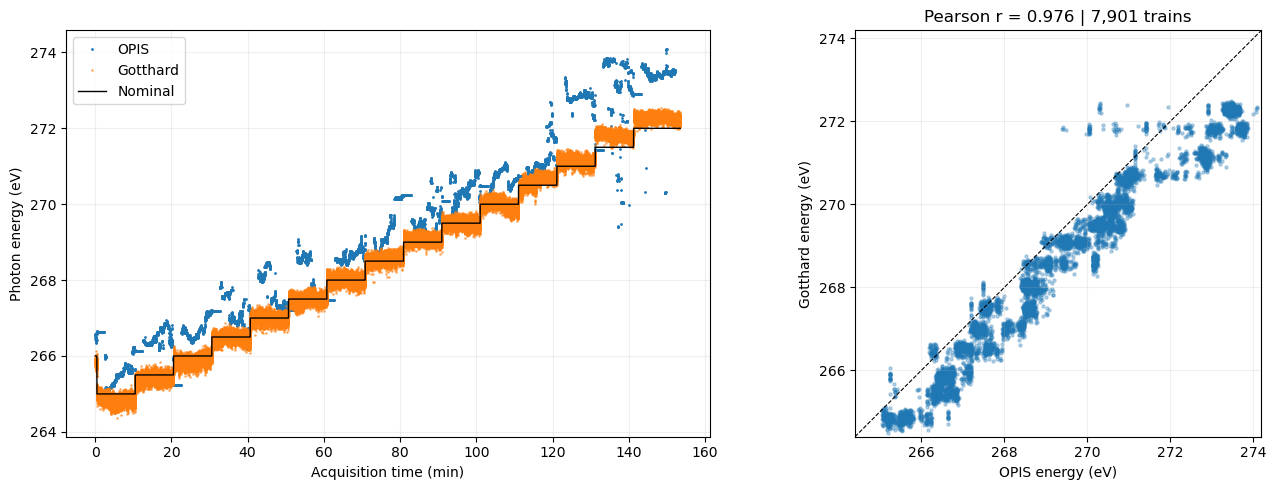

In [61]:
# One small helper to avoid undefined correlations for constant or empty data.
def pearson(x, y):
    if len(x) < 2 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(time_min[valid_opis], mpe[valid_opis], '.', ms=2, label='OPIS')
ax[0].plot(time_min[valid_vls], gotthard_E[valid_vls], '.', ms=2, alpha=0.5, label='Gotthard')
ax[0].plot(time_min, nominal, color='k', lw=1, label='Nominal')
ax[0].set(xlabel='Acquisition time (min)', ylabel='Photon energy (eV)')
ax[0].legend()

if matched.any():
    x, y = mpe[matched], gotthard_E[matched]
    r = pearson(x, y)
    lo, hi = min(x.min(), y.min()) - 0.1, max(x.max(), y.max()) + 0.1
    ax[1].scatter(x, y, s=5, alpha=0.3)
    ax[1].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    ax[1].set(xlim=(lo, hi), ylim=(lo, hi), aspect='equal')
    ax[1].set_title(f'Pearson r = {r:.3f} | {len(x):,} trains')
    print(f'OPIS:     {x.mean():.4f} ± {x.std():.4f} eV (mean ± SD)')
    print(f'Gotthard: {y.mean():.4f} ± {y.std():.4f} eV (mean ± SD)')
    print(f'Gotthard - OPIS: {(y-x).mean():+.4f} eV')
else:
    ax[1].text(0.5, 0.5, 'No matched trains', transform=ax[1].transAxes, ha='center')
ax[1].set(xlabel='OPIS energy (eV)', ylabel='Gotthard energy (eV)')
for a in ax:
    a.grid(alpha=0.2)
fig.tight_layout()
plt.show()


Binning on Gotthard energy:
Bin 1: 264.499–266.494 eV | 1,829 trains | OPIS = 266.3580 eV | Gotthard = 265.5357 eV
Bin 2: 266.494–268.490 eV | 1,951 trains | OPIS = 268.0418 eV | Gotthard = 267.4173 eV
Bin 3: 268.490–270.485 eV | 2,010 trains | OPIS = 270.0889 eV | Gotthard = 269.3570 eV
Bin 4: 270.485–272.480 eV | 2,111 trains | OPIS = 272.6418 eV | Gotthard = 271.5231 eV

OPIS:     269.4019 ± 2.4728 eV
Gotthard: 268.5722 ± 2.2939 eV
Gotthard - OPIS: -0.8296 eV


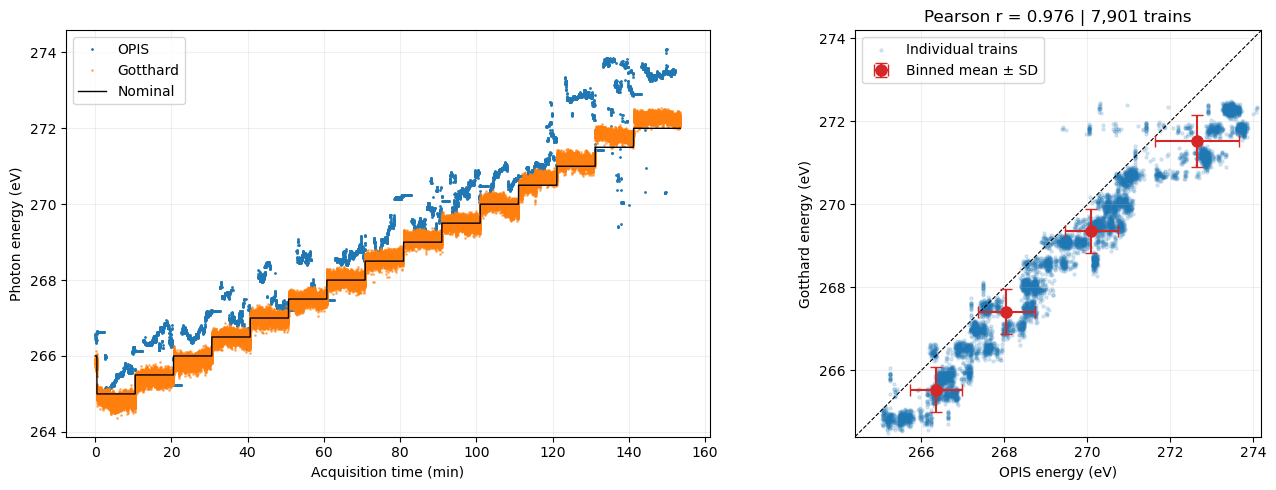

In [70]:
N_BINS = 4

# One small helper to avoid undefined correlations.
def pearson(x, y):
    if len(x) < 2 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return np.corrcoef(x, y)[0, 1]


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(time_min[valid_opis], mpe[valid_opis],
           '.', ms=2, label='OPIS')
ax[0].plot(time_min[valid_vls], gotthard_E[valid_vls],
           '.', ms=2, alpha=0.5, label='Gotthard')
ax[0].plot(time_min, nominal, color='k', lw=1, label='Nominal')

ax[0].set(xlabel='Acquisition time (min)',
          ylabel='Photon energy (eV)')
ax[0].legend()

if matched.any():

    x, y = mpe[matched], gotthard_E[matched]

    r = pearson(x, y)

    lo = min(x.min(), y.min()) - 0.1
    hi = max(x.max(), y.max()) + 0.1

    ax[1].scatter(x, y, s=5, alpha=0.15, label='Individual trains')
    ax[1].plot([lo, hi], [lo, hi], 'k--', lw=0.8)

    # Bin according to Gotthard photon energy.
    bin_edges = np.linspace(y.min(), y.max(), N_BINS + 1)

    print('\nBinning on Gotthard energy:')

    for i in range(N_BINS):

        mask = (y >= bin_edges[i]) & (y < bin_edges[i + 1])

        # Include the upper edge in the last bin.
        if i == N_BINS - 1:
            mask |= y == bin_edges[-1]

        if not mask.any():
            continue

        xb, yb = x[mask], y[mask]

        ax[1].errorbar(
            xb.mean(), yb.mean(),
            xerr=xb.std(),
            yerr=yb.std(),
            fmt='o', color='C3', ms=8,
            capsize=4,
            label='Binned mean ± SD' if i == 0 else None
        )

        print(f'Bin {i+1}: {bin_edges[i]:.3f}–'
              f'{bin_edges[i+1]:.3f} eV | '
              f'{mask.sum():,} trains | '
              f'OPIS = {xb.mean():.4f} eV | '
              f'Gotthard = {yb.mean():.4f} eV')

    ax[1].set(xlim=(lo, hi), ylim=(lo, hi), aspect='equal')
    ax[1].set_title(f'Pearson r = {r:.3f} | {len(x):,} trains')
    ax[1].legend()

    print(f'\nOPIS:     {x.mean():.4f} ± {x.std():.4f} eV')
    print(f'Gotthard: {y.mean():.4f} ± {y.std():.4f} eV')
    print(f'Gotthard - OPIS: {(y-x).mean():+.4f} eV')

else:
    ax[1].text(0.5, 0.5, 'No matched trains',
               transform=ax[1].transAxes, ha='center')

ax[1].set(xlabel='OPIS energy (eV)',
          ylabel='Gotthard energy (eV)')

for a in ax:
    a.grid(alpha=0.2)

fig.tight_layout()
plt.show()

## 4. Energy fluctuations at fixed nominal energy


266.000 eV | 24 trains | r = +0.144
265.000 eV | 506 trains | r = +0.087
265.500 eV | 513 trains | r = -0.085
266.000 eV | 525 trains | r = +0.278
266.500 eV | 527 trains | r = +0.156
267.000 eV | 526 trains | r = +0.180
267.500 eV | 525 trains | r = -0.176
268.000 eV | 526 trains | r = -0.100
268.500 eV | 503 trains | r = +0.254
269.000 eV | 522 trains | r = -0.080
269.500 eV | 513 trains | r = -0.036
270.000 eV | 511 trains | r = +0.002
270.500 eV | 524 trains | r = +0.323
271.000 eV | 527 trains | r = -0.118
271.500 eV | 526 trains | r = -0.006
272.000 eV | 579 trains | r = -0.103


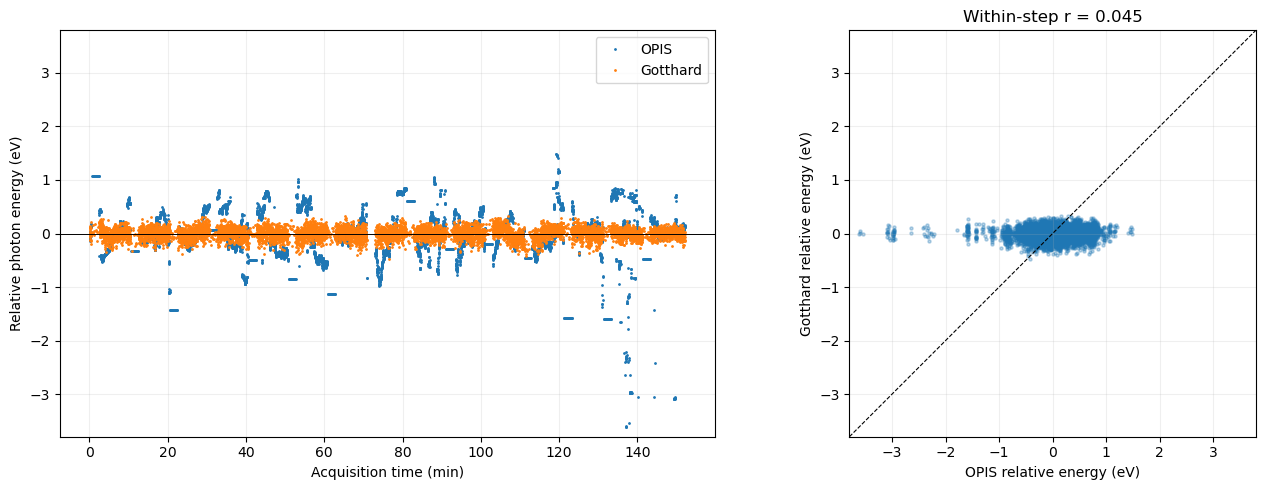

OPIS SD: 0.4662 eV | Gotthard SD: 0.1060 eV


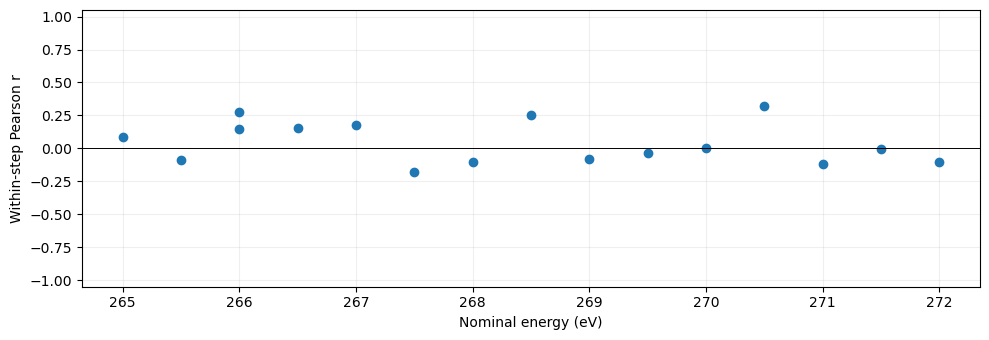

In [62]:
# Identify contiguous nominal-energy steps, including repeated settings.
changes = np.r_[True, nominal_round[1:] != nominal_round[:-1]]
step_start = np.maximum.accumulate(np.where(changes, np.arange(len(tid)), 0))
step_id = np.cumsum(changes)
settled = (tid - tid[step_start] >= SETTLE_TRAINS) if is_undulator else np.ones(len(tid), bool)
step_valid = matched & settled & np.isfinite(nominal_round) & (nominal_round > 0)

# Fixed-energy runs can still be compared if nominal-energy records are absent.
if not is_undulator:
    step_valid = matched.copy()
    step_id = np.ones(len(tid), dtype=int)

opis_rel = np.full(len(tid), np.nan)
vls_rel = np.full(len(tid), np.nan)
step_E, step_r = [], []

for s in np.unique(step_id[step_valid]):
    m = step_valid & (step_id == s)
    if m.sum() < MIN_TRAINS:
        continue
    opis_rel[m] = mpe[m] - mpe[m].mean()
    vls_rel[m] = gotthard_E[m] - gotthard_E[m].mean()
    E = np.nanmedian(nominal_round[m]) if np.isfinite(nominal_round[m]).any() else np.nan
    r_step = pearson(mpe[m], gotthard_E[m])
    step_E.append(E)
    step_r.append(r_step)
    print(f'{E:.3f} eV | {m.sum():,} trains | r = {r_step:+.3f}')

relative = np.isfinite(opis_rel) & np.isfinite(vls_rel)

if relative.any():
    x, y = opis_rel[relative], vls_rel[relative]
    lim = max(0.01, 1.05 * max(np.abs(x).max(), np.abs(y).max()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(time_min[relative], x, '.', ms=2, label='OPIS')
    ax[0].plot(time_min[relative], y, '.', ms=2, label='Gotthard')
    ax[0].axhline(0, color='k', lw=0.7)
    ax[0].set(xlabel='Acquisition time (min)', ylabel='Relative photon energy (eV)', ylim=(-lim, lim))
    ax[0].legend()
    ax[1].scatter(x, y, s=5, alpha=0.3)
    ax[1].plot([-lim, lim], [-lim, lim], 'k--', lw=0.8)
    ax[1].set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal',
              xlabel='OPIS relative energy (eV)', ylabel='Gotthard relative energy (eV)')
    ax[1].set_title(f'Within-step r = {pearson(x, y):.3f}')
    for a in ax:
        a.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    print(f'OPIS SD: {x.std():.4f} eV | Gotthard SD: {y.std():.4f} eV')
else:
    print('Not enough matched trains for the fluctuation analysis')

if is_undulator and step_E:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(step_E, step_r, 'o')
    ax.axhline(0, color='k', lw=0.7)
    ax.set(xlabel='Nominal energy (eV)', ylabel='Within-step Pearson r', ylim=(-1.05, 1.05))
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 5. Beam pointing
The horizontal and vertical monitors are train-resolved; units are not confirmed, so use recorded units. Plot the full time traces and compare both photon-energy diagnostics on the same matched sample. For undulator scans, remove the means of both energy and pointing within each settled step. Correlation alone does not establish a pointing-induced energy shift.

If OPIS is missing, the Gotthard-only pointing correlation still runs on the valid Gotthard trains.

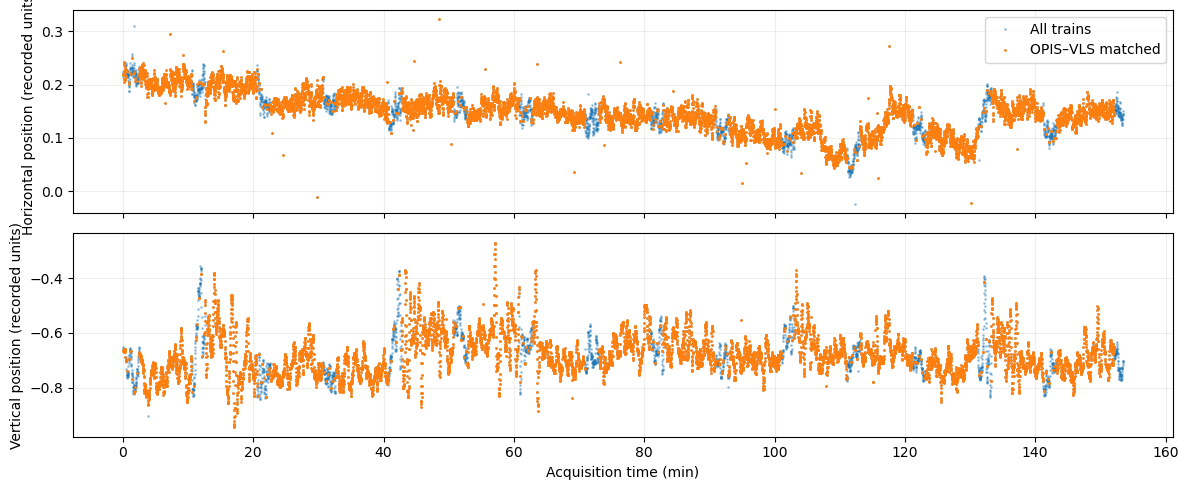

In [63]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for a, pos, label in zip(ax, (hor_pos, ver_pos), ('Horizontal', 'Vertical')):
    a.plot(time_min, pos, '.', ms=2, alpha=0.35, label='All trains')
    a.plot(time_min[matched], pos[matched], '.', ms=2, label='OPIS–VLS matched')
    a.set_ylabel(f'{label} position (recorded units)')
    a.grid(alpha=0.2)
ax[0].legend()
ax[-1].set_xlabel('Acquisition time (min)')
fig.tight_layout()
plt.show()

OPIS vs Horizontal: slope +0.9141 eV / position unit
Gotthard vs Horizontal: slope +1.456 eV / position unit
OPIS vs Vertical: slope -0.03814 eV / position unit
Gotthard vs Vertical: slope +0.06946 eV / position unit


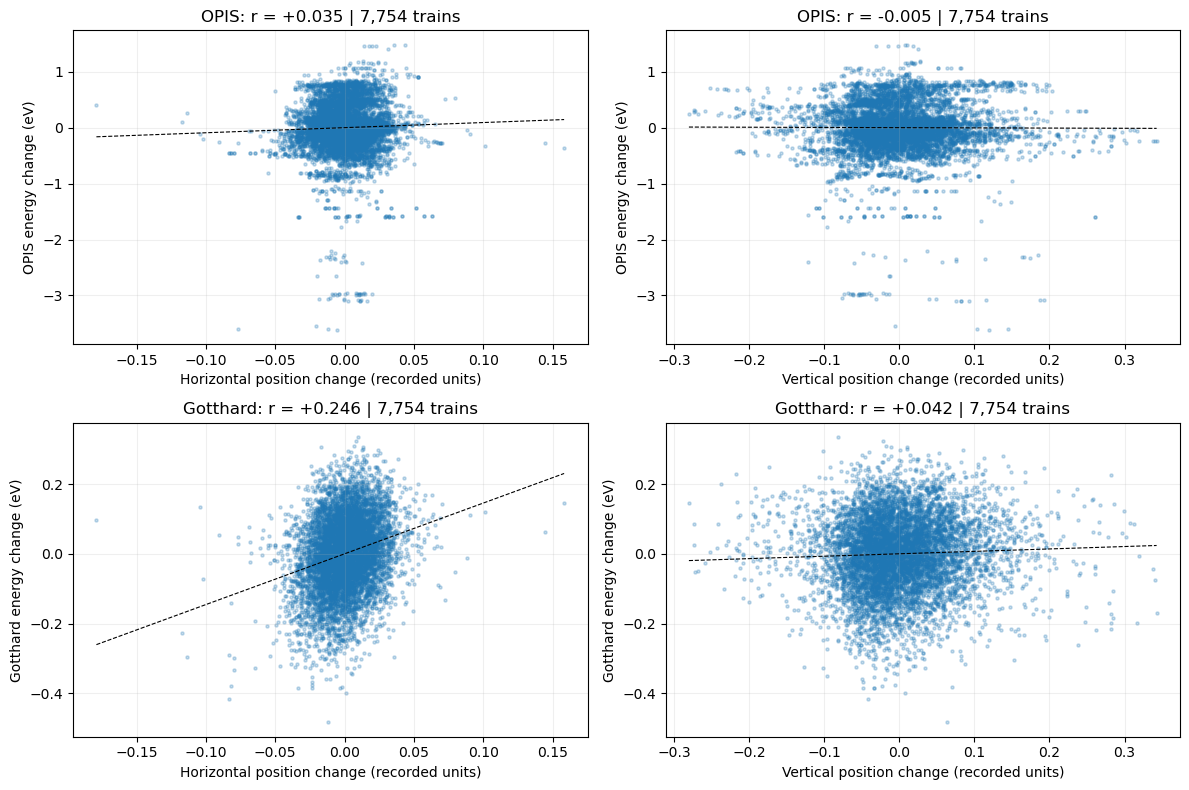

In [64]:
# Energy vs pointing, with step means removed from the same selected trains.
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Prefer the same sample for both instruments. With no usable matched OPIS,
# show a Gotthard-only diagnostic instead.
pointing_matched = relative.any()
base = relative if pointing_matched else valid_vls & settled
if not pointing_matched:
    print('No usable matched OPIS sample; Gotthard-only pointing check')

for j, (pos, label) in enumerate(zip((hor_pos, ver_pos), ('Horizontal', 'Vertical'))):
    common = base & np.isfinite(pos)
    for i, (E, name) in enumerate(zip((mpe, gotthard_E), ('OPIS', 'Gotthard'))):
        a = ax[i, j]
        m = common & np.isfinite(E)
        if i == 0 and not pointing_matched:
            m[:] = False
        pos_rel = np.full(len(tid), np.nan)
        energy_rel = np.full(len(tid), np.nan)
        for s in np.unique(step_id[m]):
            k = m & (step_id == s)
            if k.sum() < MIN_TRAINS:
                continue
            pos_rel[k] = pos[k] - pos[k].mean()
            energy_rel[k] = E[k] - E[k].mean()
        k = np.isfinite(pos_rel) & np.isfinite(energy_rel)
        if k.any():
            x, y = pos_rel[k], energy_rel[k]
            a.scatter(x, y, s=5, alpha=0.25)
            r_pos = pearson(x, y)
            a.set_title(f'{name}: r = {r_pos:+.3f} | {k.sum():,} trains')
            if np.std(x) > 0:
                coef = np.polyfit(x, y, 1)
                xx = np.array([x.min(), x.max()])
                a.plot(xx, np.polyval(coef, xx), 'k--', lw=0.8)
                print(f'{name} vs {label}: slope {coef[0]:+.4g} eV / position unit')
        else:
            a.set_title(f'{name}: no usable data')
        a.set(xlabel=f'{label} position change (recorded units)', ylabel=f'{name} energy change (eV)')
        a.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Partial covariance

Matched trains: 7,752
Correlation before: +0.047
Correlation after:  +0.040

Pointing coefficients (eV / position unit)
OPIS:     horizontal +0.9348 | vertical -0.0641
Gotthard: horizontal +1.4446 | vertical +0.0292

Energy fluctuations (standard deviation)
OPIS:     0.4658 -> 0.4655 eV
Gotthard: 0.1062 -> 0.1029 eV


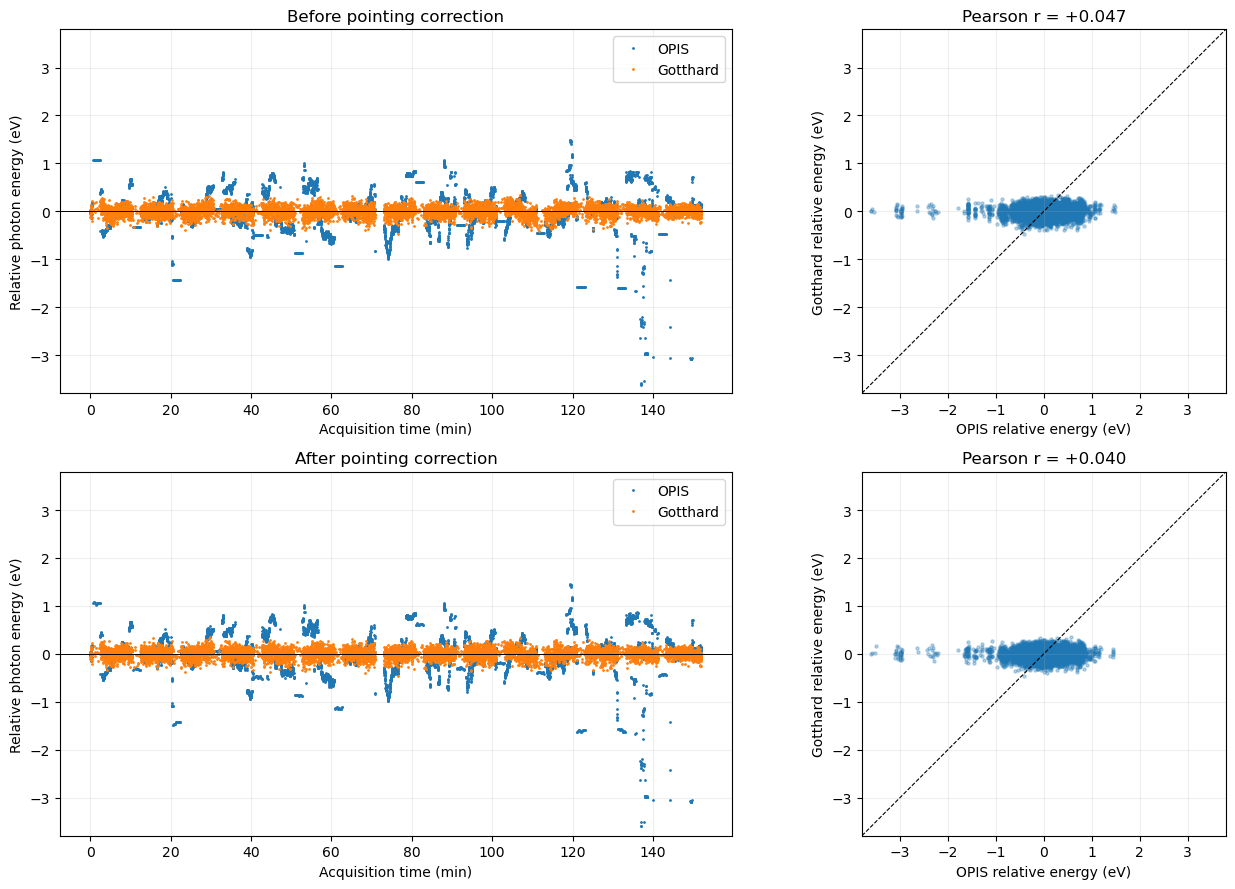

In [65]:
# ---- Partial correlation: remove beam-pointing dependence -------------------

common = (
    relative &
    np.isfinite(hor_pos) &
    np.isfinite(ver_pos)
)

# Remove the mean within each nominal energy step.
x = np.full(len(tid), np.nan)
y = np.full(len(tid), np.nan)
h = np.full(len(tid), np.nan)
v = np.full(len(tid), np.nan)

for s in np.unique(step_id[common]):

    m = common & (step_id == s)

    if m.sum() < MIN_TRAINS:
        continue

    x[m] = mpe[m] - mpe[m].mean()
    y[m] = gotthard_E[m] - gotthard_E[m].mean()

    h[m] = hor_pos[m] - hor_pos[m].mean()
    v[m] = ver_pos[m] - ver_pos[m].mean()

keep = np.isfinite(x) & np.isfinite(y) & np.isfinite(h) & np.isfinite(v)

x, y = x[keep], y[keep]
h, v = h[keep], v[keep]

# Linear regression against horizontal and vertical position.
X = np.column_stack([h, v])

coef_opis = np.linalg.lstsq(X, x, rcond=None)[0]
coef_vls = np.linalg.lstsq(X, y, rcond=None)[0]

# Residual energy fluctuations after removing pointing dependence.
opis_res = x - X @ coef_opis
vls_res = y - X @ coef_vls

r_before = pearson(x, y)
r_after = pearson(opis_res, vls_res)

print(f'Matched trains: {keep.sum():,}')
print(f'Correlation before: {r_before:+.3f}')
print(f'Correlation after:  {r_after:+.3f}')

print('\nPointing coefficients (eV / position unit)')
print(f'OPIS:     horizontal {coef_opis[0]:+.4f} | vertical {coef_opis[1]:+.4f}')
print(f'Gotthard: horizontal {coef_vls[0]:+.4f} | vertical {coef_vls[1]:+.4f}')

print('\nEnergy fluctuations (standard deviation)')
print(f'OPIS:     {x.std():.4f} -> {opis_res.std():.4f} eV')
print(f'Gotthard: {y.std():.4f} -> {vls_res.std():.4f} eV')


# Compare before and after removing pointing dependence.
lim = 1.05 * max(np.abs(x).max(), np.abs(y).max(),
                 np.abs(opis_res).max(), np.abs(vls_res).max())

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

for i, (a, b, r, label) in enumerate([
    (x, y, r_before, 'Before pointing correction'),
    (opis_res, vls_res, r_after, 'After pointing correction')
]):

    ax[i, 0].plot(time_min[keep], a, '.', ms=2, label='OPIS')
    ax[i, 0].plot(time_min[keep], b, '.', ms=2, label='Gotthard')
    ax[i, 0].axhline(0, color='k', lw=0.7)
    ax[i, 0].set(xlabel='Acquisition time (min)',
                 ylabel='Relative photon energy (eV)',
                 ylim=(-lim, lim))
    ax[i, 0].set_title(label)
    ax[i, 0].legend()

    ax[i, 1].scatter(a, b, s=5, alpha=0.3)
    ax[i, 1].plot([-lim, lim], [-lim, lim], 'k--', lw=0.8)
    ax[i, 1].set(xlabel='OPIS relative energy (eV)',
                 ylabel='Gotthard relative energy (eV)',
                 xlim=(-lim, lim), ylim=(-lim, lim),
                 aspect='equal')
    ax[i, 1].set_title(f'Pearson r = {r:+.3f}')

for a in ax.flat:
    a.grid(alpha=0.2)

fig.tight_layout()
plt.show()

## Temporal averaging

  1 s |   543 time bins | r = +0.040
  5 s |  1540 time bins | r = +0.073
 10 s |   826 time bins | r = +0.063
 30 s |   309 time bins | r = +0.073
 60 s |   161 time bins | r = +0.106


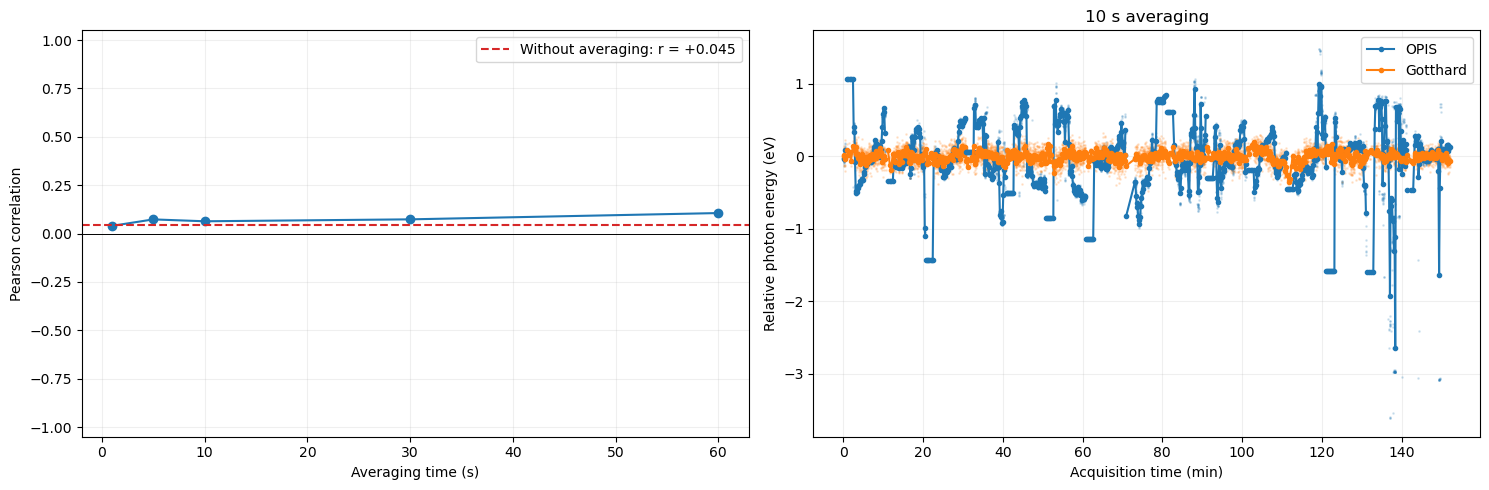

In [66]:
# ---- Temporal averaging of OPIS and Gotthard --------------------------------

AVERAGING_TIMES = [1, 5, 10, 30, 60]  # seconds
PLOT_AVERAGING = 10                  # seconds
TRAIN_RATE = 10                     # Hz
MIN_SHOTS_PER_TIME_BIN = 2

time_s = (tid - tid[0]) / TRAIN_RATE

keep_time = np.isfinite(opis_rel) & np.isfinite(vls_rel)

# Average both diagnostics over the same trains and time bins.
# Keep nominal energy steps separate.
def average_in_time(dt):

    averages = {}

    for s in np.unique(step_id[keep_time]):

        m = keep_time & (step_id == s)

        bins = np.floor(time_s[m] / dt).astype(int)
        bins, inv = np.unique(bins, return_inverse=True)

        n = np.bincount(inv)

        a = np.bincount(inv, weights=opis_rel[m]) / n
        b = np.bincount(inv, weights=vls_rel[m]) / n
        t = np.bincount(inv, weights=time_s[m]) / n

        keep = n >= MIN_SHOTS_PER_TIME_BIN

        averages[s] = (bins[keep], t[keep], a[keep], b[keep])

    return averages


# Correlation for different averaging periods.
r_raw = pearson(opis_rel[keep_time], vls_rel[keep_time])

r_avg = []
n_avg = []

for dt in AVERAGING_TIMES:

    averages = average_in_time(dt)

    a_all, b_all = [], []

    for bins, t, a, b in averages.values():

        if len(a) < 3:
            continue

        a_all.extend(a - a.mean())
        b_all.extend(b - b.mean())

    r = pearson(np.asarray(a_all), np.asarray(b_all))

    r_avg.append(r)
    n_avg.append(len(a_all))

    print(f'{dt:3d} s | {len(a_all):5d} time bins | r = {r:+.3f}')


# Plot averaging dependence and an example averaged trace.
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(AVERAGING_TIMES, r_avg, 'o-')
ax[0].axhline(r_raw, color='C3', ls='--',
              label=f'Without averaging: r = {r_raw:+.3f}')
ax[0].axhline(0, color='k', lw=0.7)
ax[0].set(xlabel='Averaging time (s)',
          ylabel='Pearson correlation',
          ylim=(-1.05, 1.05))
ax[0].legend()

ax[1].plot(time_s[keep_time] / 60, opis_rel[keep_time],
           '.', color='C0', ms=2, alpha=0.15)
ax[1].plot(time_s[keep_time] / 60, vls_rel[keep_time],
           '.', color='C1', ms=2, alpha=0.15)

averages = average_in_time(PLOT_AVERAGING)

for j, (bins, t, a, b) in enumerate(averages.values()):

    ax[1].plot(t / 60, a, 'o-', color='C0', ms=3,
               label='OPIS' if j == 0 else None)
    ax[1].plot(t / 60, b, 'o-', color='C1', ms=3,
               label='Gotthard' if j == 0 else None)

ax[1].set(xlabel='Acquisition time (min)',
          ylabel='Relative photon energy (eV)',
          title=f'{PLOT_AVERAGING} s averaging')
ax[1].legend()

for a in ax:
    a.grid(alpha=0.2)

fig.tight_layout()
plt.show()

## Time lag correction

Correlation at zero lag: +0.073
Maximum correlation: +0.137 at +40 s
Minimum correlation: +0.042 at -15 s


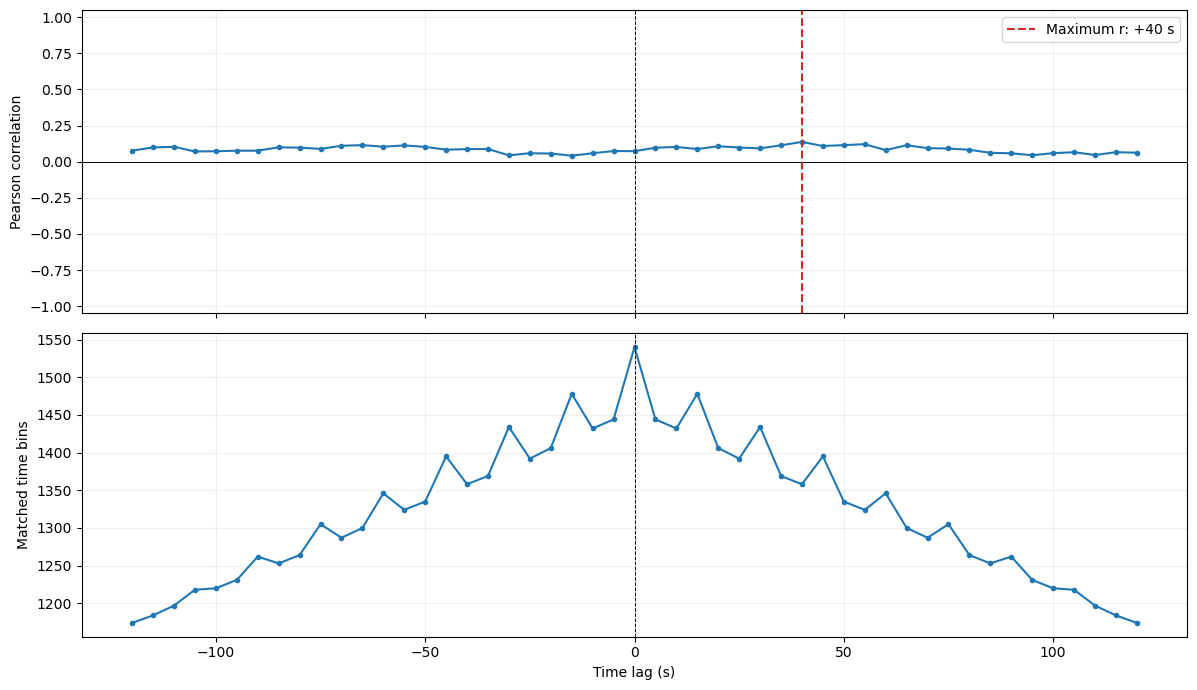

In [67]:
# ---- Time-lag correlation between OPIS and Gotthard ------------------------

TIME_BIN = 5        # seconds
MAX_LAG = 120       # seconds
MIN_PAIRS = 20

averages = average_in_time(TIME_BIN)

lags = np.arange(-MAX_LAG // TIME_BIN,
                  MAX_LAG // TIME_BIN + 1)

r_lag = np.full(len(lags), np.nan)
n_pairs = np.zeros(len(lags), dtype=int)

for j, lag in enumerate(lags):

    a_all, b_all = [], []

    for bins, t, a, b in averages.values():

        # Positive lag: Gotthard measurement occurs later than OPIS.
        # Match actual time bins, without filling missing data.
        _, ia, ib = np.intersect1d(
            bins + lag, bins, return_indices=True
        )

        if len(ia) < 3:
            continue

        aa = a[ia]
        bb = b[ib]

        # Remove the mean within each energy step.
        a_all.extend(aa - aa.mean())
        b_all.extend(bb - bb.mean())

    n_pairs[j] = len(a_all)

    if n_pairs[j] >= MIN_PAIRS:
        r_lag[j] = pearson(np.asarray(a_all),
                           np.asarray(b_all))

lag_s = lags * TIME_BIN

best = np.nanargmax(r_lag)
worst = np.nanargmin(r_lag)
zero = np.flatnonzero(lags == 0)[0]

print(f'Correlation at zero lag: {r_lag[zero]:+.3f}')

print(f'Maximum correlation: {r_lag[best]:+.3f} '
      f'at {lag_s[best]:+d} s')

print(f'Minimum correlation: {r_lag[worst]:+.3f} '
      f'at {lag_s[worst]:+d} s')


fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(lag_s, r_lag, 'o-', ms=3)
ax[0].axhline(0, color='k', lw=0.7)
ax[0].axvline(0, color='k', ls='--', lw=0.7)
ax[0].axvline(lag_s[best], color='C3', ls='--',
              label=f'Maximum r: {lag_s[best]:+d} s')

ax[0].set(ylabel='Pearson correlation',
          ylim=(-1.05, 1.05))
ax[0].legend()

ax[1].plot(lag_s, n_pairs, 'o-', ms=3)
ax[1].axvline(0, color='k', ls='--', lw=0.7)
ax[1].set(xlabel='Time lag (s)',
          ylabel='Matched time bins')

for a in ax:
    a.grid(alpha=0.2)

fig.tight_layout()
plt.show()

## 6. Optional spectral diagnostics (full VLS frames only)
Use the same accepted shots as in Section 2. For a fixed-energy run, inspect all matched trains; for an undulator scan, choose one settled nominal step to avoid mixing deliberate energy changes. The default is the middle available matched step. These plots are intensity-weighted spectral averages, unlike the equal-shot centre average used for the correlation. Stored-centre files without full VLS frames skip this section.

In [68]:
spectra_idx = np.array([], dtype=int)
if has_vls and matched.any():
    spec_mask = matched.copy()
    if is_undulator:
        spec_mask &= settled & np.isfinite(nominal_round)
        available = np.unique(nominal_round[spec_mask])
        if len(available):
            E = available[len(available)//2] if SPECTRA_NOMINAL is None else SPECTRA_NOMINAL
            spec_mask &= np.isclose(nominal_round, E, atol=0.001, rtol=0)
            print(f'Spectral diagnostics at nominal {E:.3f} eV')
    spectra_idx = np.flatnonzero(spec_mask)

if len(spectra_idx) and SHOW_EXAMPLES:
    idx = spectra_idx[np.argsort(mpe[spectra_idx])]
    examples = idx[np.unique(np.linspace(0, len(idx)-1, min(9, len(idx))).astype(int))]
    fig, axs = plt.subplots(3, 3, figsize=(17, 10), sharex=True)
    with h5py.File(FILE, 'r') as f:
        for a, k in zip(axs.flat, examples):
            V = correct_vls(f['vls'][k, b0:b1, read_roi], dark)
            spectrum = V[keep_shot[k]].mean(axis=0)
            a.plot(px, spectrum, 'k-', lw=1)
            a.axvline(centre_train[k], color='C3', label='Mean shot COM')
            a.axvline(px[np.argmax(spectrum)], color='C0', ls='--', label='Spectrum maximum')
            a.axhline(0, color='grey', lw=0.5)
            a.set_title(f'OPIS {mpe[k]:.3f} eV | {time_min[k]:.1f} min\n'
                        f'{vls_nshots[k]} shots | mean COM {centre_train[k]:.2f} px')
            a.set_xlim(PLOT_ROI or VLS_ROI)
            a.grid(alpha=0.15)
    for a in axs.flat[len(examples):]:
        a.set_visible(False)
    for a in axs[-1]:
        a.set_xlabel('Gotthard pixel')
    for a in axs[:, 0]:
        a.set_ylabel('ADU / shot')
    axs[0, 0].legend(fontsize=9)
    fig.tight_layout()
    plt.show()

    # Three trains across the OPIS range, four strongest accepted shots each.
    train_examples = idx[np.unique(np.linspace(0, len(idx)-1, min(3, len(idx))).astype(int))]
    fig, axs = plt.subplots(len(train_examples), 4, figsize=(17, 3*len(train_examples)),
                            sharex=True, squeeze=False)
    with h5py.File(FILE, 'r') as f:
        for i, k in enumerate(train_examples):
            V = correct_vls(f['vls'][k, b0:b1, read_roi], dark)
            bunches = np.flatnonzero(keep_shot[k])
            bunches = bunches[np.argsort(G[k, bunches])[::-1]][:4]
            for a, b in zip(axs[i], bunches):
                a.plot(px, V[b], 'k-', lw=0.8)
                a.axvline(shot_centres[k, b], color='C3', label='Shot COM')
                a.axvline(px[np.argmax(V[b])], color='C0', ls='--', label='Maximum')
                a.axvline(centre_train[k], color='C2', ls=':', label='Mean shot COM')
                a.axhline(0, color='grey', lw=0.5)
                a.set_title(f'OPIS {mpe[k]:.3f} eV | bunch {b+b0}\nGMD {G[k,b]:.2f} µJ')
                a.set_xlim(PLOT_ROI or VLS_ROI)
            for a in axs[i, len(bunches):]:
                a.set_visible(False)
    for a in axs[-1]:
        a.set_xlabel('Gotthard pixel')
    for a in axs[:, 0]:
        a.set_ylabel('ADU')
    axs[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print('Spectral examples skipped')

Spectral examples skipped


In [69]:
# Average full spectra in OPIS energy bins, without using COM to position them.
if len(spectra_idx) > 1 and np.ptp(mpe[spectra_idx]) > 0:
    opis_edges = np.linspace(mpe[spectra_idx].min(), mpe[spectra_idx].max(), N_OPIS_BINS+1)
    opis_bin = np.clip(np.searchsorted(opis_edges, mpe[spectra_idx], side='right')-1,
                       0, N_OPIS_BINS-1)
    spectra_sum = np.zeros((N_OPIS_BINS, len(px)))
    n_shots = np.zeros(N_OPIS_BINS, dtype=int)
    n_trains = np.zeros(N_OPIS_BINS, dtype=int)
    opis_sum = np.zeros(N_OPIS_BINS)

    with h5py.File(FILE, 'r') as f:
        for start in range(0, len(spectra_idx), CHUNK_TRAINS):
            idx = spectra_idx[start:start+CHUNK_TRAINS]
            bins = opis_bin[start:start+CHUNK_TRAINS]
            V = correct_vls(f['vls'][idx, b0:b1, read_roi], dark)
            keep = keep_shot[idx] & np.isfinite(V).all(axis=-1)
            for b in range(N_OPIS_BINS):
                m = bins == b
                selected = keep[m]
                train_keep = selected.any(axis=1)
                spectra_sum[b] += V[m][selected].sum(axis=0, dtype=float)
                n_shots[b] += selected.sum()
                n_trains[b] += train_keep.sum()
                opis_sum[b] += mpe[idx[m][train_keep]].sum()

    vls_opis_mean = np.divide(spectra_sum, n_shots[:, None],
                              out=np.full_like(spectra_sum, np.nan), where=n_shots[:, None] > 0)
    opis_mean = np.divide(opis_sum, n_trains, out=np.full(N_OPIS_BINS, np.nan), where=n_trains > 0)
    energy = np.polyval(cal_coef, px)

    # A common COM window for all bins, centred on their pooled spectrum.
    # Unlike the old fixed pixel window, this follows the actual peak at each run energy.
    peak = px[np.argmax(uniform_filter1d(spectra_sum.sum(axis=0), size=SMOOTH))]
    centre_mask = np.abs(px - peak) <= COM_HALF_WIDTH
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    colors = plt.cm.viridis(np.linspace(0, 0.9, N_OPIS_BINS))
    for b, spectrum in enumerate(vls_opis_mean):
        if n_shots[b] == 0:
            continue
        weights = np.clip(spectrum[centre_mask], 0, None)
        if weights.sum() <= 0:
            continue
        centre = np.average(px[centre_mask], weights=weights)
        y = spectrum.copy()
        if NORMALISE_PEAK:
            y /= y[centre_mask].max()
        label = f'{opis_mean[b]:.3f} eV'
        ax[0].plot(px, y, color=colors[b], label=label)
        ax[1].plot(energy[::-1], y[::-1], color=colors[b])
        ax[2].scatter(opis_mean[b], np.polyval(cal_coef, centre), color=colors[b], s=50)
        print(f'OPIS {label} | {n_trains[b]:,} trains | {n_shots[b]:,} shots')
    ax[0].axvspan(peak-COM_HALF_WIDTH, peak+COM_HALF_WIDTH, color='grey', alpha=0.1)
    ax[0].set(xlabel='Gotthard pixel', xlim=PLOT_ROI or VLS_ROI,
              ylabel='Normalised intensity' if NORMALISE_PEAK else 'ADU / shot')
    ax[0].legend(title='OPIS energy')
    ax[1].set(xlabel='Gotthard photon energy (eV)', xlim=sorted(np.polyval(cal_coef, PLOT_ROI or VLS_ROI)))
    ax[2].set(xlabel='OPIS energy (eV)', ylabel='Gotthard centre (eV)')
    ax[2].ticklabel_format(axis='y', style='plain', useOffset=False)
    for a in ax:
        a.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
else:
    print('OPIS-binned spectra skipped: need full VLS and varying matched OPIS energy')

OPIS-binned spectra skipped: need full VLS and varying matched OPIS energy


## 7. Undulator scan calibration check
Compare the calibration stored in the current file against the reference. This is a diagnostic only: it does not replace `cal_coef` or change any previous result. For a fixed-energy delay scan no new calibration is fitted.

In [11]:
if is_undulator:
    with h5py.File(FILE, 'r') as f:
        has_cal = all('photon_energy/' + k in f for k in ('cal_coef', 'cal_centres', 'cal_energies'))
        if has_cal:
            run_coef = f['photon_energy/cal_coef'][:]
            run_px = f['photon_energy/cal_centres'][:]
            run_E = f['photon_energy/cal_energies'][:]
            print('Stored calibration:', run_coef)
            print('Reference calibration:', cal_coef)
            print('Stored processing attributes:', dict(f['photon_energy'].attrs))
    if has_cal:
        residuals = run_E - np.polyval(run_coef, run_px)
        px_fit = np.linspace(run_px.min(), run_px.max(), 200)
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        ax[0].plot(run_px, run_E, 'o', label='Current calibration points')
        ax[0].plot(px_fit, np.polyval(run_coef, px_fit), 'k--', label='Current fit')
        ax[0].plot(px_fit, np.polyval(cal_coef, px_fit), 'C3-', label='Reference 60560')
        ax[0].set(xlabel='Gotthard pixel', ylabel='Photon energy (eV)')
        ax[0].legend()
        ax[1].plot(run_E, residuals, '.-', label='Current fit residual')
        ax[1].plot(run_E, run_E-np.polyval(cal_coef, run_px), '.-', label='Reference residual')
        ax[1].axhline(0, color='k', lw=0.7)
        ax[1].set(xlabel='Photon energy (eV)', ylabel='Residual (eV)')
        ax[1].legend()
        fig.tight_layout()
        plt.show()
        print('Current fit RMS (eV):', np.sqrt(np.mean(residuals**2)))
    else:
        print('No stored calibration for this undulator scan')
else:
    print('Fixed-energy scan: no new calibration required')

Fixed-energy scan: no new calibration required


### Notes
- If the file contains neither full VLS frames nor stored centres, use the raw-run extraction workflow (`analysis/scripts/photon_energy.py`, as used for 60586). For a fixed-energy scan, do not fit a new slope from that scan alone; use the reference calibration with extracted pixel centres.
- NaN/zero OPIS records are missing measurements, not zero-energy photons. A lack of valid OPIS values does not establish that the instrument was physically off.
- To change runs, change the header and run all cells. The notebook never reassigns `FILE` or the reference calibration later.